In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from qitp.simulation.backend import SimulatorBackend

In [5]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [20]:
depth=2
dt=1e-1
nqubits = 6

In [10]:
nsteps=50
target=0.3

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [12]:
from qiskit.quantum_info import SparsePauliOp

h = 0.25
J = 0.25

paulis = [
    # Campo trasverso
    "XIIIII",  # X_0
    "IXIIII",  # X_1
    "IIXIII",  # X_2
    "IIIXII",  # X_3
    "IIIIXI",  # X_4
    "IIIIIX",  # X_5

    # Interazioni orizzontali
    "ZZIIII",  # Z_0 Z_1
    "IZZIII",  # Z_1 Z_2
    "IIIZZI",  # Z_3 Z_4
    "IIIIZZ",  # Z_4 Z_5

    # Interazioni verticali
    "ZIIZII",  # Z_0 Z_3
    "IZIIZI",  # Z_1 Z_4
    "IIZIIZ",  # Z_2 Z_5
]

coeffs = [
    h, h, h, h, h, h,
    J, J, J, J,
    J, J, J
]

H = SparsePauliOp(paulis, coeffs=coeffs)

In [22]:
from qiskit.quantum_info import SparsePauliOp

Mz = []
for i in range(nqubits):
    p = ["I"] * nqubits
    p[i] = "Y"
    Mz.append(
        SparsePauliOp(["".join(p)], coeffs=[1.0])
    )

Identity = SparsePauliOp(
    ["I" * nqubits],
    coeffs=[1.0]
)

In [24]:
H_eff = H + sum(Mz[1:], start=Mz[0])# + Identity

In [26]:
rotations = []

for constraint in Mz:

    rotations.append(
        constraint_rotation(
            constraint,
            target
        )
    )

In [28]:
rho = density_from_rotations(nqubits, rotations, degree=2)

seeds = support_only(rho)

In [30]:
basis = CommutatorBasis.from_seed(hamiltonian=H_eff, seeds=seeds, depth=depth)

In [32]:
len(basis.paulis)

209

In [34]:
circuit = prepare_state(
    nqubits,
    rotations
)

In [36]:
circuit = circuit.decompose()

In [38]:
approx = UnitaryApproximation(basis, trot=4)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    backend,
    approx
)

prop.constraints = [
    Identity]
prop.constraints.extend(Mz)

In [40]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [42]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps,
    state=psi #Remove for exponential advantage
)

energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
circuit = results["circuit"]

In [43]:
print(np.round(energies[-1],3))

-2.005


In [44]:
print(np.round(magnetizations[-1],3))

[0.269 0.272 0.262 0.263 0.267 0.264]


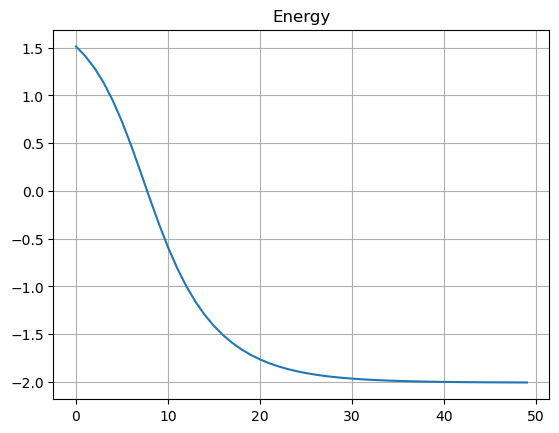

In [45]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

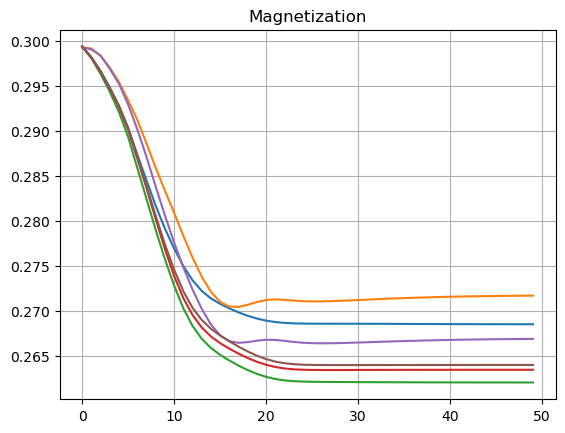

In [46]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [64]:
import numpy as np
from scipy.optimize import root

Hm = H.to_matrix()

C = []
for i in range(nqubits):
    p = ["I"] * nqubits
    p[i] = "Y"
    C.append(
        SparsePauliOp(["".join(p)], coeffs=[1.0]).to_matrix()
    )

def constraints_of_lambda(lmbda):

    H_eff2 = Hm.copy()

    for a, Ck in zip(lmbda, C):
        H_eff2 += a * Ck

    eigvals, eigvecs = np.linalg.eigh(H_eff2)

    psi = eigvecs[:, 0]

    return np.array([
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        ) - target
        for Ck in C
    ])

sol = root(
    constraints_of_lambda,
    x0=np.zeros(nqubits)
)

print("lambdas =", sol.x)

H_eff2 = Hm.copy()

for a, Ck in zip(sol.x, C):
    H_eff2 += a * Ck

eigvals, eigvecs = np.linalg.eigh(H_eff2)

psi = eigvecs[:, 0]

energy = np.real(
    np.vdot(
        psi,
        Hm @ psi
    )
)

print("Constrained energy =", energy)

for i, Ck in enumerate(C):
    print(
        f"constraint {i}",
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        )
    )

lambdas = [-0.12996667 -0.16415694 -0.12996667 -0.12996667 -0.16415694 -0.12996667]
Constrained energy = -1.979913086041175
constraint 0 0.30000000000240035
constraint 1 0.2999999999973382
constraint 2 0.3000000000024
constraint 3 0.30000000000240074
constraint 4 0.29999999999733845
constraint 5 0.3000000000024005


In [66]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-2.11 -2.08 -1.45 -1.43 -1.21 -1.18 -1.18 -1.08 -0.98 -0.98 -0.91 -0.87
 -0.82 -0.7  -0.7  -0.64 -0.64 -0.62 -0.5  -0.48 -0.42 -0.41 -0.34 -0.28
 -0.25 -0.25 -0.25 -0.25 -0.15 -0.07 -0.04 -0.04  0.04  0.04  0.07  0.15
  0.25  0.25  0.25  0.25  0.28  0.34  0.41  0.42  0.48  0.5   0.62  0.64
  0.64  0.7   0.7   0.82  0.87  0.91  0.98  0.98  1.08  1.18  1.18  1.21
  1.43  1.45  2.08  2.11]
